# Navojoa Climate — Original Time-Series Analysis (Annotated)

**Based on the author's original notebook.** The original sequence, calculations and existing visual outputs are preserved. Comments and short explanations have been added in English so readers can follow the reasoning step by step.

**Source:** historical daily observations from Mexican National Meteorological Service (SMN), station 26131 in Navojoa, Sonora. The records have uneven coverage; missing observations must not be interpreted as zeros.

In [1]:
%matplotlib inline
#-----------------------------------------------------------------------------------------------------------------------------
# This step prepares the dataset for the analysis in this section.
#-----------------------------------------------------------------------------------------------------------------------------


# CLIMATOLOGICAL DATASET

# STATION: 26131
# NAME: NAVOJOA (FFCC)
# STATE: SONORA
# MUNICIPALITY: NAVOJOA
# LATITUDE: 027.081°
# LONGITUDE: -109.445°
# ELEVATION: 41 meters above sea level
#EMISION   : 06/04/2020

# Import the Python libraries needed for data manipulation, plotting and analysis.
import numpy as np
import pandas as pd
# Draw and label the plot to display the selected meteorological observations.
import seaborn as sns
import matplotlib.pyplot as plt
# Import the Python libraries needed for data manipulation, plotting and analysis.
import statsmodels.api as sm


## 1. Load and prepare the observations

Read the station's text file, convert missing-value markers, remove the entirely empty evaporation column, and parse dates. We keep this preprocessing close to the original implementation so the workflow remains recognizable.

In [2]:
#-----------------------------------------------------------------------------------------------------------------------------
# Clean the original table by removing unusable entries and representing missing values consistently.
#-----------------------------------------------------------------------------------------------------------------------------

# This step prepares the dataset for the analysis in this section.
df0 = pd.read_csv('ClimatologiaNavojoa.txt', skiprows=19, sep='\s+', names=["Fecha", "Precip (mm)", "Evap (mm)","Tmax (°C)","Tmin (°C)"]) 

# Clean the original table by removing unusable entries and representing missing values consistently.
df0.replace("Nulo", np.nan, inplace=True)

# Clean the original table by removing unusable entries and representing missing values consistently.
df0.drop("Evap (mm)", axis=1, inplace=True)
# Import the Python libraries needed for data manipulation, plotting and analysis.
df0.drop(13404, axis=0, inplace=True)

# Clean the original table by removing unusable entries and representing missing values consistently.
df0["Precip (mm)"]= pd.to_numeric(df0["Precip (mm)"])
df0["Tmax (°C)"]= pd.to_numeric(df0["Tmax (°C)"])
df0["Tmin (°C)"]= pd.to_numeric(df0["Tmin (°C)"]) 

# Use the date column or a date range to select the observations of interest.
df=df0.copy()

# Use the date column or a date range to select the observations of interest.
df["Fecha"]= pd.to_datetime(df["Fecha"], dayfirst=True)

# Use the date column or a date range to select the observations of interest.
df["Mes"]= df['Fecha'].dt.month
df["Año"]= df['Fecha'].dt.year

# This step prepares the dataset for the analysis in this section.
df.head()

/tmp/ipykernel_2549/226825927.py:12: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df0.drop("Evap (mm)", axis=1, inplace=True)
/tmp/ipykernel_2549/226825927.py:14: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df0.drop(13404, axis=0, inplace=True)


,Fecha,Precip (mm),Tmax (°C),Tmin (°C),Mes,Año
0,1931-01-01,0.0,28.0,8.0,1,1931
1,1931-01-02,0.0,29.0,7.0,1,1931
2,1931-01-03,0.0,29.0,9.0,1,1931
3,1931-01-04,0.0,29.0,6.0,1,1931
4,1931-01-05,0.0,26.0,5.0,1,1931


## 2. Make dates the time-series index

A time-series index lets us select observations by a year or a date range using pandas `.loc`. It also allows moving windows to be computed along the chronological observations.

In [3]:
# Use the date column or a date range to select the observations of interest.

# Prepare the working DataFrame and use dates as the time-series index.
df_st = df.copy()
# Use the date column or a date range to select the observations of interest.
df_st = df_st.set_index('Fecha')

# This step prepares the dataset for the analysis in this section.
df_st.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 13404 entries, 1931-01-01 to 1993-07-31
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Precip (mm)  13370 non-null  float64
 1   Tmax (°C)    13322 non-null  float64
 2   Tmin (°C)    13293 non-null  float64
 3   Mes          13404 non-null  int32  
 4   Año          13404 non-null  int32  
dtypes: float64(3), int32(2)
memory usage: 523.6 KB


In [4]:
# Use the date column or a date range to select the observations of interest.
df_st

,Precip (mm),Tmax (°C),Tmin (°C),Mes,Año
Fecha,,,,,
1931-01-01,0.0,28.0,8.0,1,1931
1931-01-02,0.0,29.0,7.0,1,1931
1931-01-03,0.0,29.0,9.0,1,1931
1931-01-04,0.0,29.0,6.0,1,1931
1931-01-05,0.0,26.0,5.0,1,1931
...,...,...,...,...,...
1993-07-27,0.0,39.0,24.0,7,1993
1993-07-28,0.0,39.0,22.0,7,1993
1993-07-29,4.5,40.0,23.0,7,1993


## 3. Inspect the historical daily records

These plots let us examine missing periods, daily variability and differences among precipitation, maximum temperature and minimum temperature. A large number of missing days may distort comparisons.

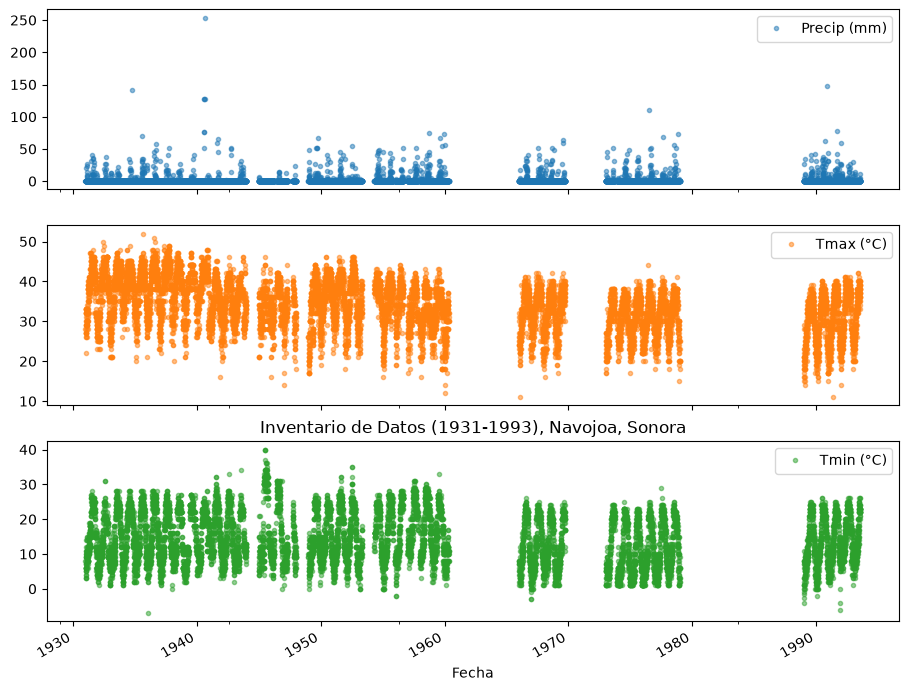

In [5]:
# Draw and label the plot to display the selected meteorological observations.

cols_plot = ['Precip (mm)', 'Tmax (°C)', 'Tmin (°C)']
ax_ylabels = ['Precip (mm)', 'Evap (mm)', 'Tmax ºC', 'Tmin (ºC)']
axes = df_st[cols_plot].plot(marker='.', alpha=0.5, linestyle='None', 
                                  figsize=(11, 9), subplots=True)
plt.title('Inventario de Datos (1931-1993), Navojoa, Sonora');

## 4. Plot precipitation over the historical record

A horizontal reference line shows the mean of the **available daily precipitation measurements**. It is not an annual or monthly rainfall total.

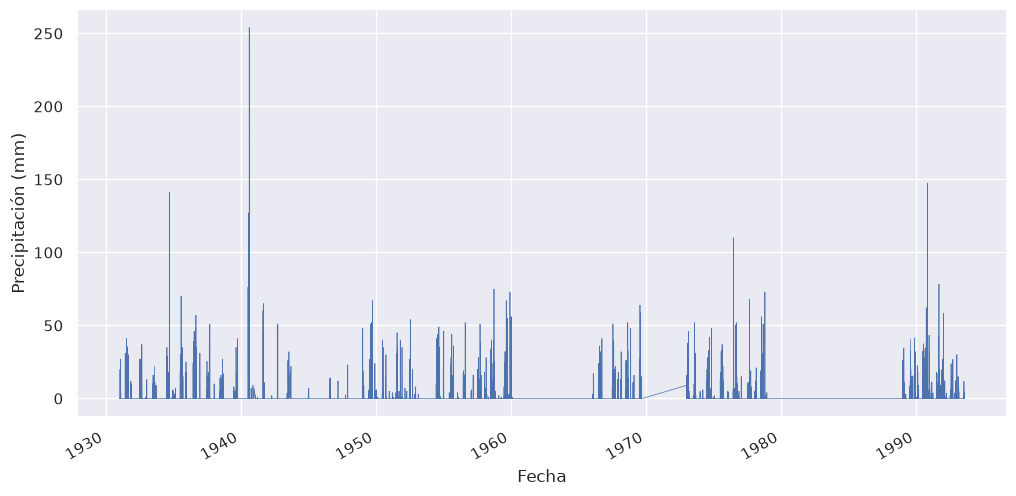

In [6]:
# Draw and label the plot to display the selected meteorological observations.
sns.set(rc={'figure.figsize':(12, 6)})

# Calculate or display the average of available observations for this selected series.
Precip_mean = df_st['Precip (mm)'].mean()


# Use the date column or a date range to select the observations of interest.
df_st['Precip (mm)'].plot(linewidth=0.5);
plt.ylabel('Precipitación (mm)');



## 5. Plot recorded daily maximum temperatures

The mean line provides context for daily fluctuations. The chart alone does not establish a statistically significant long-term trend.

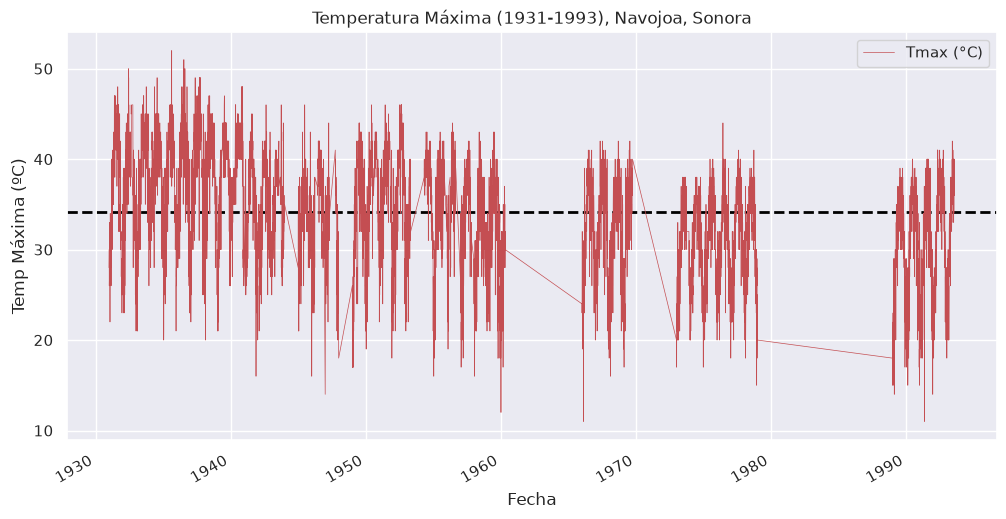

In [7]:
# Use the date column or a date range to select the observations of interest.

# Use the date column or a date range to select the observations of interest.
sns.set(rc={'figure.figsize':(12, 6)})

# Calculate or display the average of available observations for this selected series.
Tmax_mean = df_st["Tmax (°C)"].mean()


# Calculate or display the average of available observations for this selected series.
plt.axhline(Tmax_mean, color = 'black', linestyle='--', linewidth=2);

# Draw and label the plot to display the selected meteorological observations.
df_st['Tmax (°C)'].plot(linewidth=0.5, color="r");
plt.ylabel('Temp Máxima (ºC)');
plt.title('Temperatura Máxima (1931-1993), Navojoa, Sonora')

plt.legend();

## 6. Plot recorded daily minimum temperatures

Compare the variability and overall level with the maximum-temperature series.

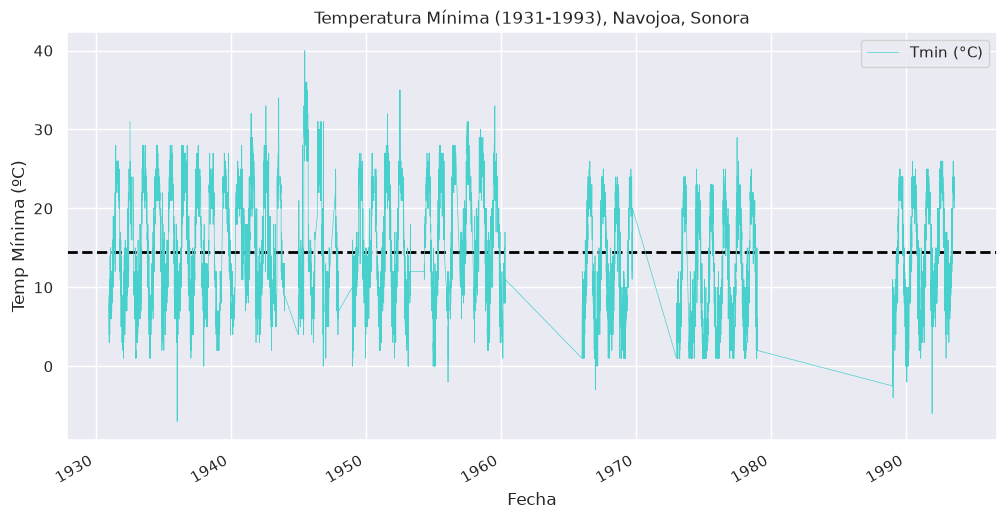

In [8]:
# Use the date column or a date range to select the observations of interest.

# Use the date column or a date range to select the observations of interest.
sns.set(rc={'figure.figsize':(12, 6)})

# Calculate or display the average of available observations for this selected series.
Tmin_mean = df_st["Tmin (°C)"].mean()


## Calculate or display the average of available observations for this selected series.
plt.axhline(Tmin_mean, color = 'black', linestyle='--', linewidth=2);

# Draw and label the plot to display the selected meteorological observations.
df_st['Tmin (°C)'].plot(linewidth=0.5, color="#48D1CC");
plt.ylabel('Temp Mínima (ºC)');
plt.title('Temperatura Mínima (1931-1993), Navojoa, Sonora')

plt.legend();

## 7. Zoom in: precipitation during 1977

Selecting one year allows daily changes and gaps to be examined more closely.

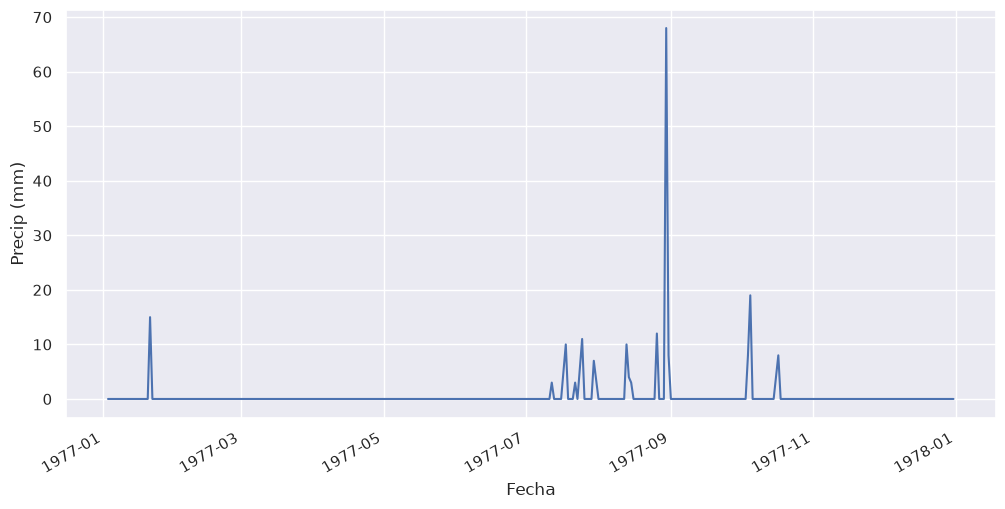

In [9]:
# Use the date column or a date range to select the observations of interest.
ax = df_st.loc['1977', 'Precip (mm)'].plot()
ax.set_ylabel('Precip (mm)');

## 8. Zoom in: a short interval in 1977

The shorter interval makes individual rainy and dry observations easier to see, without treating missing measurements as dry days.

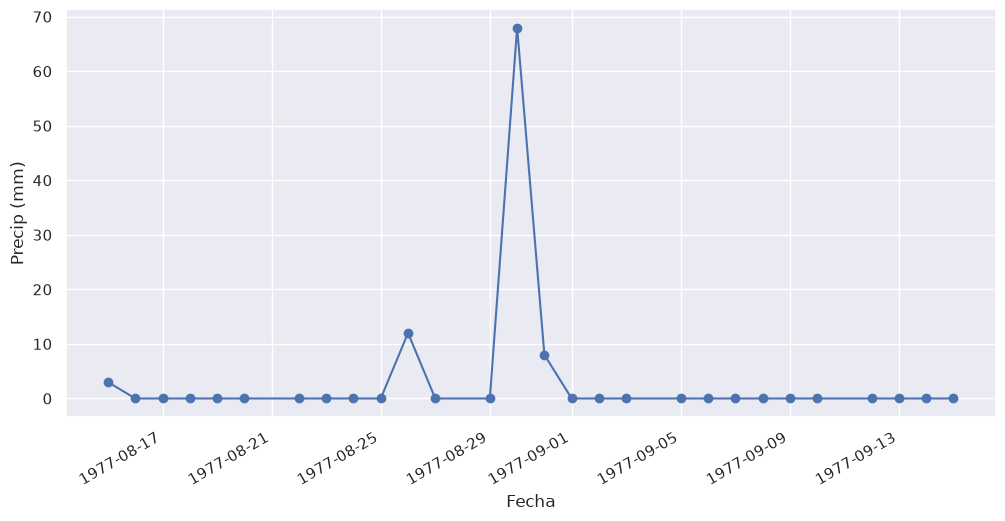

In [10]:
# Use the date column or a date range to select the observations of interest.
ax = df_st.loc['1977-08-15':'1977-09-15', 'Precip (mm)'].plot(marker='o', linestyle='-')
ax.set_ylabel('Precip (mm)');

## 9. Compare maximum temperatures from 1973 to 1977

Use date slicing to focus on the selected period rather than the entire station record.

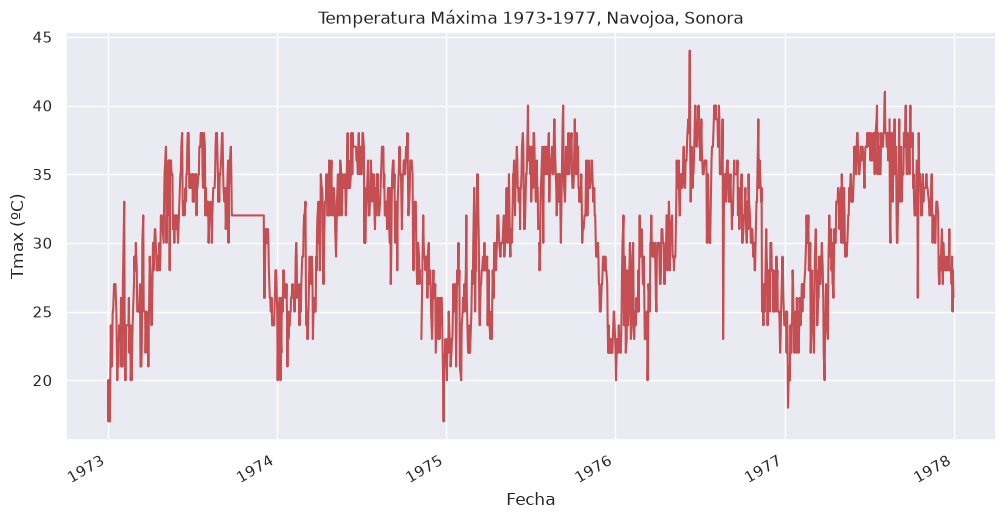

In [11]:
# Use the date column or a date range to select the observations of interest.
sns.set(rc={'figure.figsize':(12, 6)})

ax = df_st.loc['1973':'1977', "Tmax (°C)"].plot(color="r")
ax.set_ylabel('Tmax (ºC)');
ax.set_title('Temperatura Máxima 1973-1977, Navojoa, Sonora');

## 10. Compare minimum temperatures from 1973 to 1977

Using the same period supports a direct visual comparison of maximum and minimum temperature behavior.

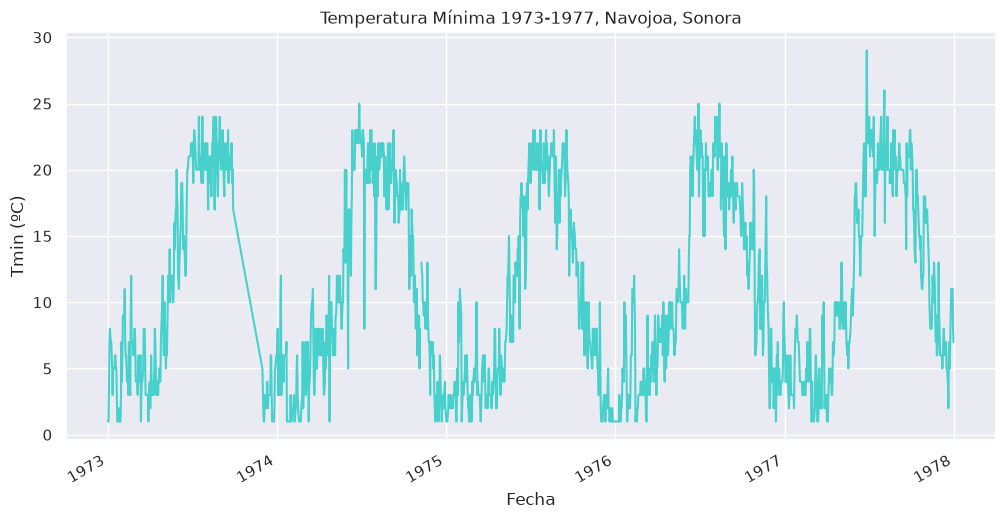

In [12]:
# Use the date column or a date range to select the observations of interest.
sns.set(rc={'figure.figsize':(12, 6)})

ax = df_st.loc['1973':'1977', "Tmin (°C)"].plot(color="#48D1CC")
ax.set_ylabel('Tmin (ºC)');
ax.set_title('Temperatura Mínima 1973-1977, Navojoa, Sonora');

## 11. Smooth temperature fluctuations with moving averages

Moving averages calculate a mean over neighboring observations. Windows of **7, 30 and 365 observations** were used in the original code. Because this data is not explicitly reindexed to include every missing calendar day, a 365-row rolling window is **not necessarily 365 calendar days**. This distinction matters when interpreting the curves.

In [13]:
#-----------------------------------------------------------------------------------------------------------------------------
# This cell compares the original values with an appropriately labeled moving average.
#-----------------------------------------------------------------------------------------------------------------------------


# This cell compares the original values with an appropriately labeled moving average.
# A moving average smooths fluctuations by averaging nearby observed values.
# This cell compares the original values with an appropriately labeled moving average.


# This cell compares the original values with an appropriately labeled moving average.
data_cols = ['Precip (mm)', 'Tmax (°C)', 'Tmin (°C)']
df_st_7d = df_st[data_cols].rolling(7, center=True).mean()
df_st_30d = df_st[data_cols].rolling(30, center=True).mean()
df_st_365d = df_st[data_cols].rolling(365, center=True).mean()


## 12. Maximum temperature: daily observations versus 7-point average

The rolling curve removes some short-term fluctuations, while the original daily values remain visible.

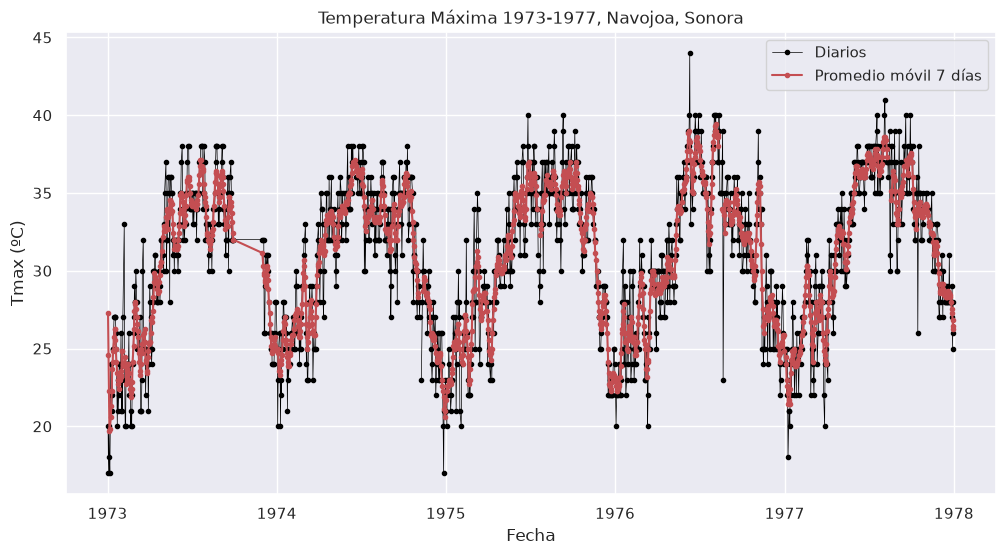

In [14]:
# Use the date column or a date range to select the observations of interest.
start, end = '1973-01', '1977-12'

# This cell compares the original values with an appropriately labeled moving average.
sns.set(rc={'figure.figsize':(12, 6)})

fig, ax = plt.subplots()
ax.plot(df_st.loc[start:end, 'Tmax (°C)'],
marker='.', linestyle='-', linewidth=0.5, label='Diarios', color="black")
ax.plot(df_st_7d.loc[start:end, 'Tmax (°C)'], marker='.', linestyle='-', label='Promedio móvil 7 días', color="r")

ax.set_xlabel('Fecha')
ax.set_ylabel('Tmax (ºC)')
ax.set_title('Temperatura Máxima 1973-1977, Navojoa, Sonora')
ax.legend();

## 13. Minimum temperature: daily observations versus 7-point average

Use the same method for daily minimum temperatures to make the comparison consistent.

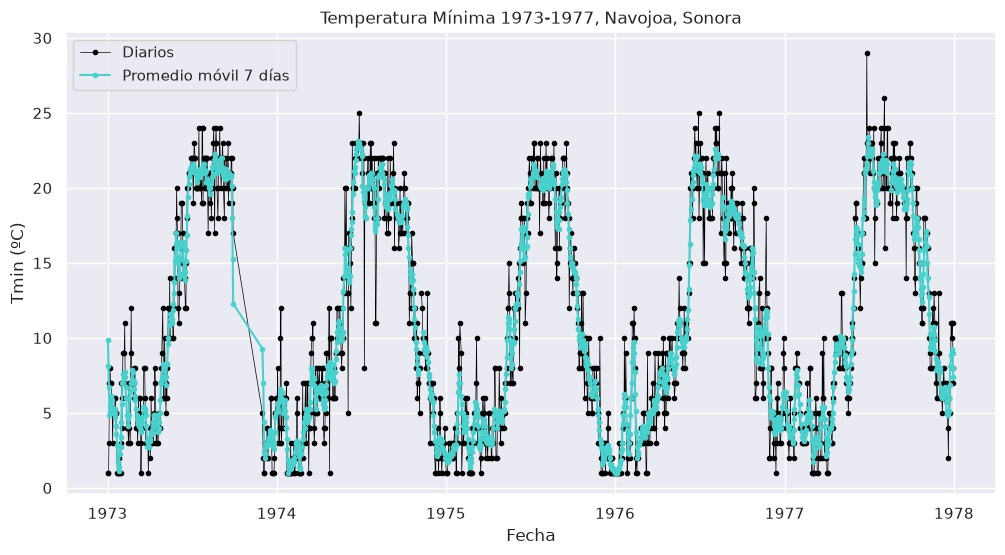

In [15]:
# Use the date column or a date range to select the observations of interest.
start, end = '1973-01', '1977-12'

# This cell compares the original values with an appropriately labeled moving average.
sns.set(rc={'figure.figsize':(12, 6)})

fig, ax = plt.subplots()
ax.plot(df_st.loc[start:end, 'Tmin (°C)'],
marker='.', linestyle='-', linewidth=0.5, label='Diarios', color="black")
ax.plot(df_st_7d.loc[start:end, 'Tmin (°C)'], marker='.', linestyle='-', label='Promedio móvil 7 días', color="#48D1CC")

ax.set_xlabel('Fecha')
ax.set_ylabel('Tmin (ºC)')
ax.set_title('Temperatura Mínima 1973-1977, Navojoa, Sonora')
ax.legend();

## 14. Maximum temperature: 1935–1939 and longer smoothing windows

The 30- and 365-observation curves emphasize progressively slower changes; they should not be described as formal climate-trend estimates.

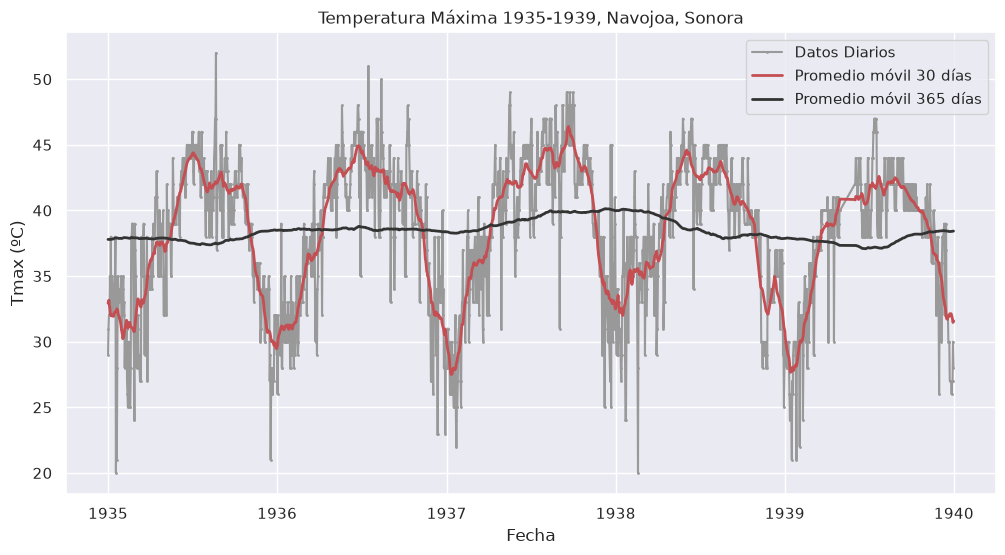

In [16]:
# Use the date column or a date range to select the observations of interest.

# Use the date column or a date range to select the observations of interest.
start, end = '1935-01', '1939-12'

# This cell compares the original values with an appropriately labeled moving average.
sns.set(rc={'figure.figsize':(12, 6)})

fig, ax = plt.subplots()
ax.plot(df_st.loc[start:end, 'Tmax (°C)'],
marker='.', markersize=2, linestyle='-', color='0.6',label='Datos Diarios')
#ax.plot(df_90_7d.loc[start:end, 'Tmax'], linestyle='-', label='Promedio móvil 7 días')
ax.plot(df_st_30d.loc[start:end, 'Tmax (°C)'], linestyle='-', linewidth=2, label='Promedio móvil 30 días', color="r")
ax.plot(df_st_365d.loc[start:end, 'Tmax (°C)'], linestyle='-', color='0.2', linewidth=2, label='Promedio móvil 365 días')

ax.set_xlabel('Fecha')
ax.set_ylabel('Tmax (ºC)')
ax.set_title('Temperatura Máxima 1935-1939, Navojoa, Sonora')
ax.legend();

## 15. Minimum temperature: 1935–1939 and longer smoothing windows

Longer windows summarize broad fluctuations but can also conceal short-lived extremes.

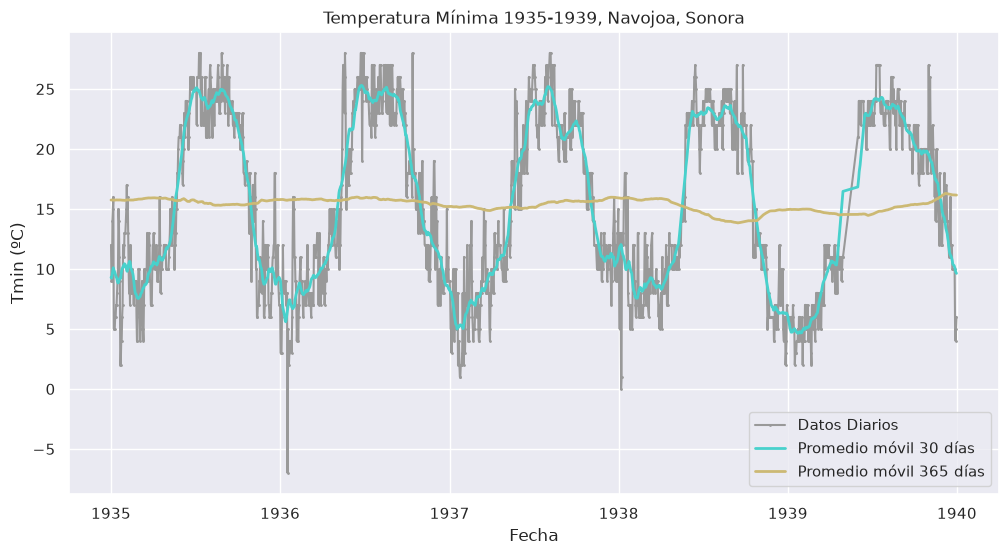

In [17]:
# Use the date column or a date range to select the observations of interest.

# Use the date column or a date range to select the observations of interest.
start, end = '1935-01', '1939-12'

# This cell compares the original values with an appropriately labeled moving average.
sns.set(rc={'figure.figsize':(12, 6)})

fig, ax = plt.subplots()
ax.plot(df_st.loc[start:end, 'Tmin (°C)'],
marker='.', markersize=2, linestyle='-', color='0.6',label='Datos Diarios')
#ax.plot(df_90_7d.loc[start:end, 'Tmax'], linestyle='-', label='Promedio móvil 7 días')
ax.plot(df_st_30d.loc[start:end, 'Tmin (°C)'], linestyle='-', linewidth=2, label='Promedio móvil 30 días', color="#48D1CC")
ax.plot(df_st_365d.loc[start:end, 'Tmin (°C)'], linestyle='-', color='y', linewidth=2, label='Promedio móvil 365 días')

ax.set_xlabel('Fecha')
ax.set_ylabel('Tmin (ºC)')
ax.set_title('Temperatura Mínima 1935-1939, Navojoa, Sonora')
ax.legend();

## 16. Compare the long-window curves

The final visualization places maximum and minimum temperatures in a shared arrangement to compare their smoothed behavior.

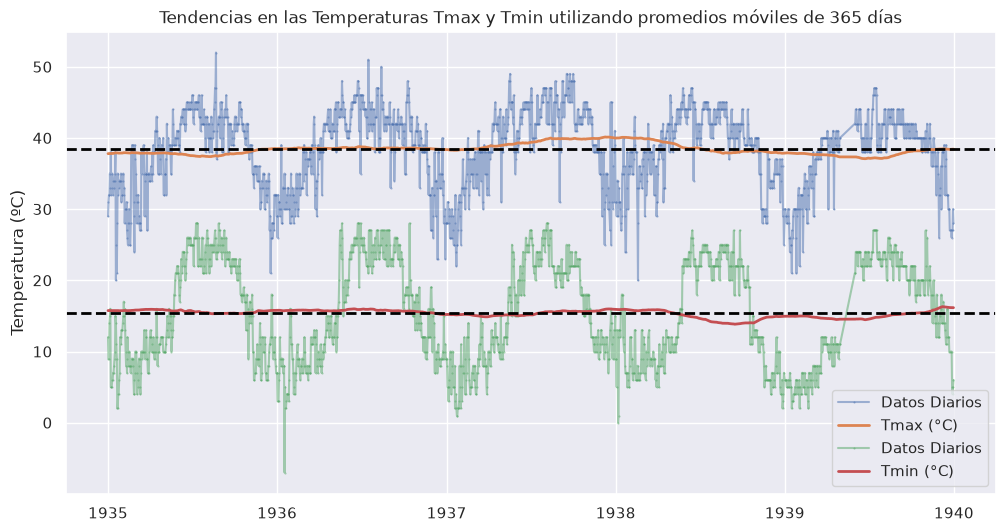

In [18]:
# This cell compares the original values with an appropriately labeled moving average.
sns.set(rc={'figure.figsize':(12, 6)})
# Use the date column or a date range to select the observations of interest.
start, end = '1935-01', '1939-12'

fig, ax = plt.subplots()
# Draw and label the plot to display the selected meteorological observations.
for nm in ['Tmax (°C)', 'Tmin (°C)']:
    ax.plot(df_st.loc[start:end, nm], marker='.', markersize=1, linestyle='-', alpha=0.5, label='Datos Diarios')
    ax.plot(df_st_365d.loc[start:end, nm], linewidth=2, label=nm)
    plt.axhline(df_st.loc[start:end, nm].mean(), color = 'black', linestyle='--', linewidth=2);
    
    ax.legend()
    ax.set_ylabel('Temperatura (ºC)')
    ax.set_title('Tendencias en las Temperaturas Tmax y Tmin utilizando promedios móviles de 365 días');


## 17. Interpretation and limitations

The original investigation explores several time scales of the station record, from daily events to smoothed multi-year windows. Incomplete data coverage, uneven intervals and the difference between *observations* and *calendar days* limit what we can conclude from the moving averages. This notebook is an exploratory visualization of historical weather observations, not an estimate of a climate-change trend.
